# Project 1, Part B: test the models in your world

Needs the Part A checkpoints and `my_models.py`, and your photos in `p1/photos/` (layout and file names: see P1_0 and the handout).
Models: A2 (concatenated features), A4, A6-H, unchanged until B5. Predictions are always 19-way; each model gets your photos at its own input size (`load_photo(path, 64)` or `224`).

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [40]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/p1
versions: python 3.13.18, torch 2.14.1+cpu, torchvision 0.29.1+cpu, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu none


{'python': '3.13.18',
 'torch': '2.14.1+cpu',
 'torchvision': '0.29.1+cpu',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'none'}

In [41]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'car', 'cat']     # TODO: your five classes (same in every notebook)

device: cpu


In [42]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [43]:
# Helpers for this notebook, built on my_models.py from P1_A: the same classes, checkpoint files, statistics and
# preprocessing as P1_A (a2_stats.npz + a2_concat.pt, a4_stats.npz + a4.pt, a6_h_stats.npz + a6_h.pt).
import os
from pathlib import Path
import timm
from my_models import A2Linear, A4ResNet, A6ViT, preprocess_a2, preprocess_a4, preprocess_a6

NUM_CLASSES = 19
A6_NAME = "vit_tiny_patch16_224.augreg_in21k_ft_in1k"


def mean_per_class_accuracy(y_true, predictions, classes=range(19)):
    """C^-1 sum_c correct_c / total_c; predictions are labels or (N, 19) scores, always among all 19 classes."""
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    if predictions.ndim == 2:
        predictions = predictions.argmax(axis=1)
    per_class = {c: float((predictions[y_true == c] == c).mean()) for c in list(classes)}
    return float(np.mean(list(per_class.values()))), per_class


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def resize_to(images, size):
    images = np.asarray(images)
    if images.shape[1:3] == (size, size):
        return images
    return np.stack([cv2.resize(i, (size, size), interpolation=cv2.INTER_AREA) for i in images])


def a6_stats(model):
    return np.asarray(model.pretrained_cfg["mean"], np.float32), np.asarray(model.pretrained_cfg["std"], np.float32)


@torch.no_grad()
def predict_proba(model, images, prep, device, idx=None, batch_size=128):
    """Softmax over all 19 classes for images[idx] (uint8, N x H x W x 3), batch by batch."""
    model.eval()
    images = images if isinstance(images, np.ndarray) else np.stack(images)
    idx = np.arange(len(images)) if idx is None else np.asarray(idx)
    out = []
    for s in range(0, len(idx), batch_size):
        xb = prep(images[idx[s:s + batch_size]]).to(device)
        out.append(F.softmax(model(xb).float(), dim=1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, NUM_CLASSES), np.float32)


def load_model(name, ckpt_dir, device):
    """'A2' (concatenated features), 'A4', 'A6-H' or 'A6-H-repaired', each with its P1_A preprocessing.
    Returns (model in eval mode, prep), where prep maps uint8 images (N, H, W, 3) to the model's input tensor."""
    ck = Path(ckpt_dir)
    state = lambda f: torch.load(ck / f, map_location="cpu", weights_only=True)
    if name == "A2":
        stats = dict(np.load(ck / "a2_stats.npz"))
        sd = state("a2_concat.pt")
        model = A2Linear(sd["linear.weight"].shape[1])
        model.load_state_dict(sd)
        prep = lambda imgs: preprocess_a2(resize_to(imgs, 64), stats, "concat")
    elif name == "A4":
        st = np.load(ck / "a4_stats.npz")
        mean, std = st["mean"], st["std"]
        model = A4ResNet()
        model.load_state_dict(state("a4.pt"))
        prep = lambda imgs: preprocess_a4(resize_to(imgs, 64), mean, std)
    elif name in ("A6-H", "A6-H-repaired"):
        st = np.load(ck / "a6_h_stats.npz")
        mean, std = st["mean"], st["std"]
        model = A6ViT(pretrained=False)
        model.load_state_dict(state("a6_h.pt" if name == "A6-H" else "a6_h_repaired.pt"))
        prep = lambda imgs: preprocess_a6(imgs, mean, std, "cpu")
    else:
        raise ValueError(name)
    return model.to(device).eval(), prep

In [44]:
CHOSEN_FACTOR = 'distance'          # our third B3 factor (milestone): 'viewpoint', 'lighting', or 'distance'
check_photos(MY_CLASSES, CHOSEN_FACTOR)   # lists missing photos; rerun after adding photos (add b5_factor= for B5)

5 problems:
  B5/adapt/bicycle: redbike1, redbike2 is a B3 object
  B5/adapt/bottle: fiji, poland is a B3 object
  B5/adapt/chair: whitechair, woodchair is a B3 object
  B5/adapt/car: darkcar, whitesuv is a B3 object
  B5/adapt/cat: siamese is a B3 object


False

In [45]:
# Load A2 (concatenated features: statistics and classifier), A4 and A6-H from CKPT_DIR, each with its P1_A preprocessing.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

X64, y, img_id, is_test = load_crops(64)
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
my_idx = [CLASSES.index(c) for c in MY_CLASSES]
MODEL_NAMES = ["A2", "A4", "A6-H"]
MODELS = {name: load_model(name, CKPT_DIR, DEV) for name in MODEL_NAMES}
SIZE = {"A2": 64, "A4": 64, "A6-H": 224}                   # each model gets the photos at its own input size
for name, (m, _) in MODELS.items():
    print(f"Loaded {name}: {count_params(m):,} parameters")


def acc5(true, pred):
    """Mean per-class accuracy over our five classes (those present); predictions are always among all 19 classes."""
    true, pred = np.asarray(true), np.asarray(pred)
    present = [c for c in my_idx if (true == c).any()]
    if not present:
        return float("nan"), {}
    return mean_per_class_accuracy(true, pred, classes=present)

Loaded A2: 34,751 parameters
Loaded A4: 701,619 parameters
Loaded A6-H: 5,528,083 parameters


In [ ]:
# Reload check: VOC test mean per-class accuracy (19 classes) of each reloaded model must match Table 1 from P1_A.
X224, _, _, _ = load_crops(224)                          # also needed for B5; 2.5 GB, kept as uint8
VOC_TEST_PROBS = {}
for name, key in [("A2", "a2_concat"), ("A4", "a4"), ("A6-H", "a6_h")]:
    model, prep = MODELS[name]
    images = X224 if SIZE[name] == 224 else X64
    VOC_TEST_PROBS[name] = predict_proba(model, images, prep, DEV, idx=idx_test, batch_size=128)
    acc, _ = mean_per_class_accuracy(y[idx_test], VOC_TEST_PROBS[name])
    saved = float(np.load(Path(CKPT_DIR) / f"{key}_test.npz")["mean_per_class_acc"])
    ok = abs(acc - saved) < 1e-3
    print(f"{name:5s} test {acc:.2%} | Table 1 {saved:.2%} | {'OK' if ok else 'MISMATCH: check preprocessing'}")
    assert ok, name

A2    test 43.72% | Table 1 43.72% | OK
A4    test 54.97% | Table 1 54.97% | OK
A6-H  test 92.20% | Table 1 92.20% | OK


## B1: ordinary photos

In [ ]:
B1_DIR = os.path.join(PHOTO_DIR, 'B1')
X1_64, y1, paths1 = load_photo_folder(B1_DIR, 64)
X1_224, _, _ = load_photo_folder(B1_DIR, 224)
print(len(y1), 'B1 photos')

50 B1 photos


In [ ]:
   !unzip -o -q /content/p1_photos_B1_cat.zip -d /content/tmp_cat
   !cp -r /content/tmp_cat/photos/B1/cat "$PHOTO_DIR/B1/"
   import glob; print(len(glob.glob(PHOTO_DIR + '/B1/cat/*.jpg')), "cat photos")

10 cat photos


In [ ]:
import zipfile, shutil, os, glob
src = "/content/p1_photos_B1_B3.zip"
tmp = "/content/tmp_photos"
shutil.rmtree(tmp, ignore_errors=True)
zipfile.ZipFile(src).extractall(tmp)
for part in ("B1", "B3"):
    shutil.copytree(os.path.join(tmp, "photos", part), os.path.join(PHOTO_DIR, part), dirs_exist_ok=True)
print("B1 photo:", len(glob.glob(PHOTO_DIR + "/B1/*/*.jpg")))
print("B3 photo:", len(glob.glob(PHOTO_DIR + "/B3/*/*/*.jpg")))

B1 photo: 52
B3 photo: 40


In [ ]:
# B1: mean per-class accuracy over our five classes on the ordinary photos, against VOC test accuracy on the same five classes.
X1 = {64: X1_64, 224: X1_224}
B1_PROBS = {name: predict_proba(m, X1[SIZE[name]], prep, DEV) for name, (m, prep) in MODELS.items()}

rows = []
for name in MODEL_NAMES:
    b1_acc, b1_pc = acc5(y1, B1_PROBS[name].argmax(1))
    voc_acc, voc_pc = mean_per_class_accuracy(y[idx_test], VOC_TEST_PROBS[name], classes=my_idx)
    row = {"model": name, "B1 (5 classes)": b1_acc, "VOC test (5 classes)": voc_acc}
    for c in my_idx:
        row[f"B1 {CLASSES[c]}"] = b1_pc.get(c, np.nan)
        row[f"VOC {CLASSES[c]}"] = voc_pc[c]
    rows.append(row)
b1_table = pd.DataFrame(rows)
b1_table.to_csv(Path(RESULTS_DIR) / "b1_results.csv", index=False)
print("B1 photos per class:", {CLASSES[c]: int((y1 == c).sum()) for c in my_idx})
display(b1_table.style.format({c: "{:.0%}" for c in b1_table.columns if c != "model"}).hide(axis="index"))

# Every B1 photo with each model's prediction (check that no person appears in any photo you show)
per_photo = pd.DataFrame({"photo": [os.path.basename(p) for p in paths1], "class": [CLASSES[c] for c in y1],
                          **{name: [CLASSES[k] for k in B1_PROBS[name].argmax(1)] for name in MODEL_NAMES}})
per_photo.to_csv(Path(RESULTS_DIR) / "b1_per_photo.csv", index=False)
display(per_photo)

cols = 10
rows_n = int(np.ceil(len(y1) / cols))
fig, ax = plt.subplots(rows_n, cols, figsize=(1.8 * cols, 2.1 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for i in range(len(y1)):
    a = ax.flat[i]
    a.imshow(X1_224[i])
    pred = CLASSES[B1_PROBS["A6-H"][i].argmax()]
    a.set_title(f"A6-H: {pred}", fontsize=7, color="green" if pred == CLASSES[y1[i]] else "red")
fig.suptitle("B1 photos with A6-H predictions (green = correct)")
plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "B1_photos.png", dpi=120)
plt.show()

**B2** is a written prediction in the milestone (which factor hurts A6-H most, which model is most robust to each), made before you shoot or evaluate B3. No code.

## B3: controlled series

Set your chosen factor, load the series, run the three models, plot one panel per factor, and export `b3_results.csv`.

In [ ]:
B3_DIR = os.path.join(PHOTO_DIR, 'B3')                     # CHOSEN_FACTOR is set at the top
recs64 = load_b3_series(B3_DIR, 64, CHOSEN_FACTOR)
recs224 = load_b3_series(B3_DIR, 224, CHOSEN_FACTOR)
print(len(recs64), 'B3 images')
assert len(recs64) == len(recs224) and all(a["object"] == b["object"] and a["condition"] == b["condition"]
                                           for a, b in zip(recs64, recs224))
X3 = {64: np.stack([r["image"] for r in recs64]), 224: np.stack([r["image"] for r in recs224])}
y3 = np.array([r["cls"] for r in recs224])
B3_PROBS = {name: predict_proba(m, X3[SIZE[name]], prep, DEV) for name, (m, prep) in MODELS.items()}

rows = b3_rows(recs64, 'A2', B3_PROBS["A2"]) + b3_rows(recs64, 'A4', B3_PROBS["A4"]) + \
       b3_rows(recs224, 'A6-H', B3_PROBS["A6-H"])
write_b3_csv(rows, os.path.join(RESULTS_DIR, 'b3_results.csv'))

90 B3 images
wrote 270 rows to /content/drive/MyDrive/p1/results/b3_results.csv


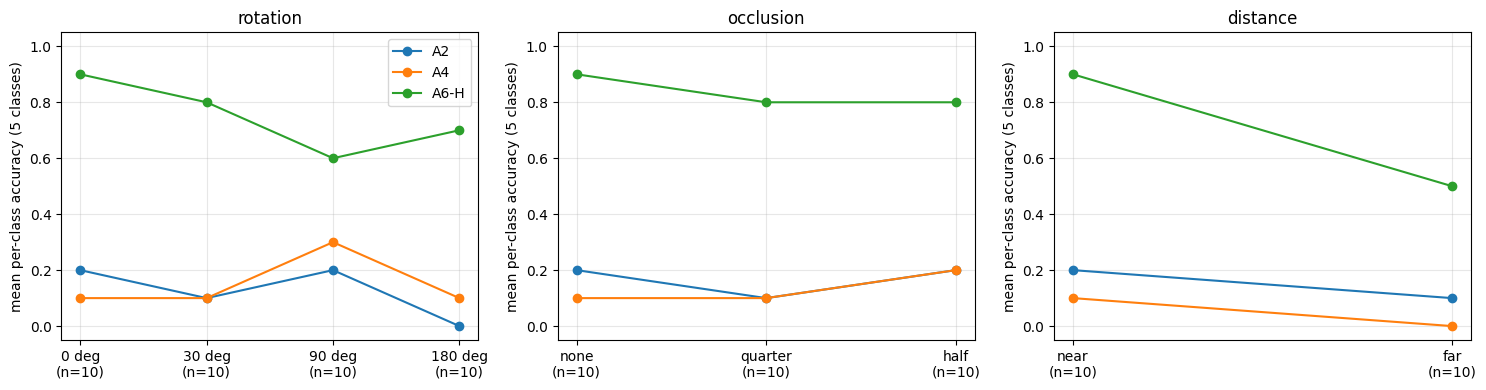

factor,condition,n,A2,A4,A6-H
rotation,0,10,0.2,0.1,0.9
rotation,30,10,0.1,0.1,0.8
rotation,90,10,0.2,0.3,0.6
rotation,180,10,0.0,0.1,0.7
occlusion,none,10,0.2,0.1,0.9
occlusion,quarter,10,0.1,0.1,0.8
occlusion,half,10,0.2,0.2,0.8
distance,near,10,0.2,0.1,0.9
distance,far,10,0.1,0.0,0.5


factor                 rotation                occlusion               \
condition                     0   30   90  180      none quarter half   
object           model                                                  
bicycle/redbike1 A2         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  1.0  1.0       1.0     1.0  1.0   
bicycle/redbike2 A2         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  1.0  1.0       1.0     1.0  1.0   
bottle/fiji      A2         0.0  0.0  1.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  1.0  0.0       0.0     0.0  0.0   
                 A6-H       0.0  0.0  0.0  0.0       0.0     0.0  0.0   
bottle/poland    A2         0.0  0.0  1.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  1.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  0.0  0.0  0.0       1.0     1.0  1.0   
car/darkcar      A2         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A4         1.0  0.0  0.0  0.0       1.0     1.0  1.0   
                 A6-H       1.0  1.0  0.0  1.0       1.0     1.0  1.0   
car/whitesuv     A2         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  0.0  1.0       1.0     1.0  1.0   
cat/siamese      A2         0.0  1.0  0.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  1.0  1.0       1.0     1.0  1.0   
cat/tabby        A2         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A4         0.0  0.0  0.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  1.0  1.0       1.0     1.0  1.0   
chair/whitechair A2         1.0  0.0  0.0  0.0       1.0     1.0  1.0   
                 A4         0.0  0.0  0.0  1.0       0.0     0.0  1.0   
                 A6-H       1.0  1.0  1.0  0.0       1.0     0.0  0.0   
chair/woodchair  A2         1.0  0.0  0.0  0.0       1.0     0.0  1.0   
                 A4         0.0  1.0  1.0  0.0       0.0     0.0  0.0   
                 A6-H       1.0  1.0  1.0  1.0       1.0     1.0  1.0   

factor                 distance       
condition                  near  far  
object           model                
bicycle/redbike1 A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  1.0  
bicycle/redbike2 A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  1.0  
bottle/fiji      A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       0.0  0.0  
bottle/poland    A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  0.0  
car/darkcar      A2         0.0  0.0  
                 A4         1.0  0.0  
                 A6-H       1.0  1.0  
car/whitesuv     A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  1.0  
cat/siamese      A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  1.0  
cat/tabby        A2         0.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  0.0  
chair/whitechair A2         1.0  0.0  
                 A4         0.0  0.0  
                 A6-H       1.0  0.0  
chair/woodchair  A2         1.0  1.0  
                 A4         0.0  0.0  
                 A6-H       1.0  0.0

In [ ]:
# B3 results: one panel per factor, each model's mean per-class accuracy over our five classes at each condition, with the
# number of photos. Rotation, occlusion and distance are severity scales, so they are drawn as lines.
FACTORS = REQUIRED_FACTORS + [CHOSEN_FACTOR]


def cond_acc(model, factor, cond):
    sel = [i for i, r in enumerate(recs224) if r["factor"] == factor and r["condition"] == cond]
    if not sel:
        return float("nan"), 0
    return acc5(y3[sel], B3_PROBS[model][sel].argmax(1))[0], len(sel)


B3_ACC = {(m, f, c): cond_acc(m, f, c) for m in MODEL_NAMES for f in FACTORS for c in B3_FACTORS[f]}

fig, axes = plt.subplots(1, len(FACTORS), figsize=(5 * len(FACTORS), 4))
for ax, f in zip(axes, FACTORS):
    conds = B3_FACTORS[f]
    x = np.arange(len(conds))
    categorical = f in ("viewpoint", "lighting")
    for k, m in enumerate(MODEL_NAMES):
        accs = [B3_ACC[(m, f, c)][0] for c in conds]
        if categorical:
            ax.plot(x + (k - 1) * 0.08, accs, "o", ms=8, label=m)
        else:
            ax.plot(x, accs, "-o", label=m)
    labels = [f"{c}{' deg' if f == 'rotation' else ''}\n(n={B3_ACC[(MODEL_NAMES[0], f, c)][1]})" for c in conds]
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f)
    ax.set_ylabel("mean per-class accuracy (5 classes)")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "B3_panels.png", dpi=150)
plt.show()

acc_table = pd.DataFrame([{"factor": f, "condition": c, "n": B3_ACC[(MODEL_NAMES[0], f, c)][1],
                           **{m: B3_ACC[(m, f, c)][0] for m in MODEL_NAMES}} for f in FACTORS for c in B3_FACTORS[f]])
acc_table.to_csv(Path(RESULTS_DIR) / "b3_accuracy.csv", index=False)
display(acc_table.style.format({m: "{:.1f}" for m in MODEL_NAMES}).hide(axis="index"))

# Each object's outcomes: 1 = correct, 0 = wrong, one row per object and model
outcomes = pd.DataFrame([{"object": r["object"], "model": m, "factor": r["factor"], "condition": r["condition"],
                          "correct": int(B3_PROBS[m][i].argmax() == r["cls"])}
                         for m in MODEL_NAMES for i, r in enumerate(recs224)])
per_object = outcomes.pivot_table(index=["object", "model"], columns=["factor", "condition"], values="correct")
per_object = per_object[[(f, c) for f in FACTORS for c in B3_FACTORS[f] if (f, c) in per_object.columns]]
per_object.to_csv(Path(RESULTS_DIR) / "b3_per_object.csv")
display(per_object)

## B4: three minimal pairs

,object,factor,condition,flips,base_p,manip_p,drop
25,car/darkcar,rotation,90,True,0.999994,1.459519e-02,0.985399
31,car/whitesuv,rotation,90,True,0.999866,2.929555e-02,0.970571
23,bottle/poland,distance,far,True,0.961432,4.000962e-07,0.961432
18,bottle/poland,rotation,30,True,0.961432,2.563013e-03,0.958869
19,bottle/poland,rotation,90,True,0.961432,1.175827e-01,0.843850
59,chair/woodchair,distance,far,True,0.998480,1.829637e-01,0.815516
20,bottle/poland,rotation,180,True,0.961432,1.855344e-01,0.775898
47,cat/tabby,distance,far,True,0.999869,3.815260e-01,0.618343
53,chair/whitechair,distance,far,True,0.395825,1.149044e-03,0.394676
50,chair/whitechair,rotation,180,True,0.395825,3.635313e-02,0.359472


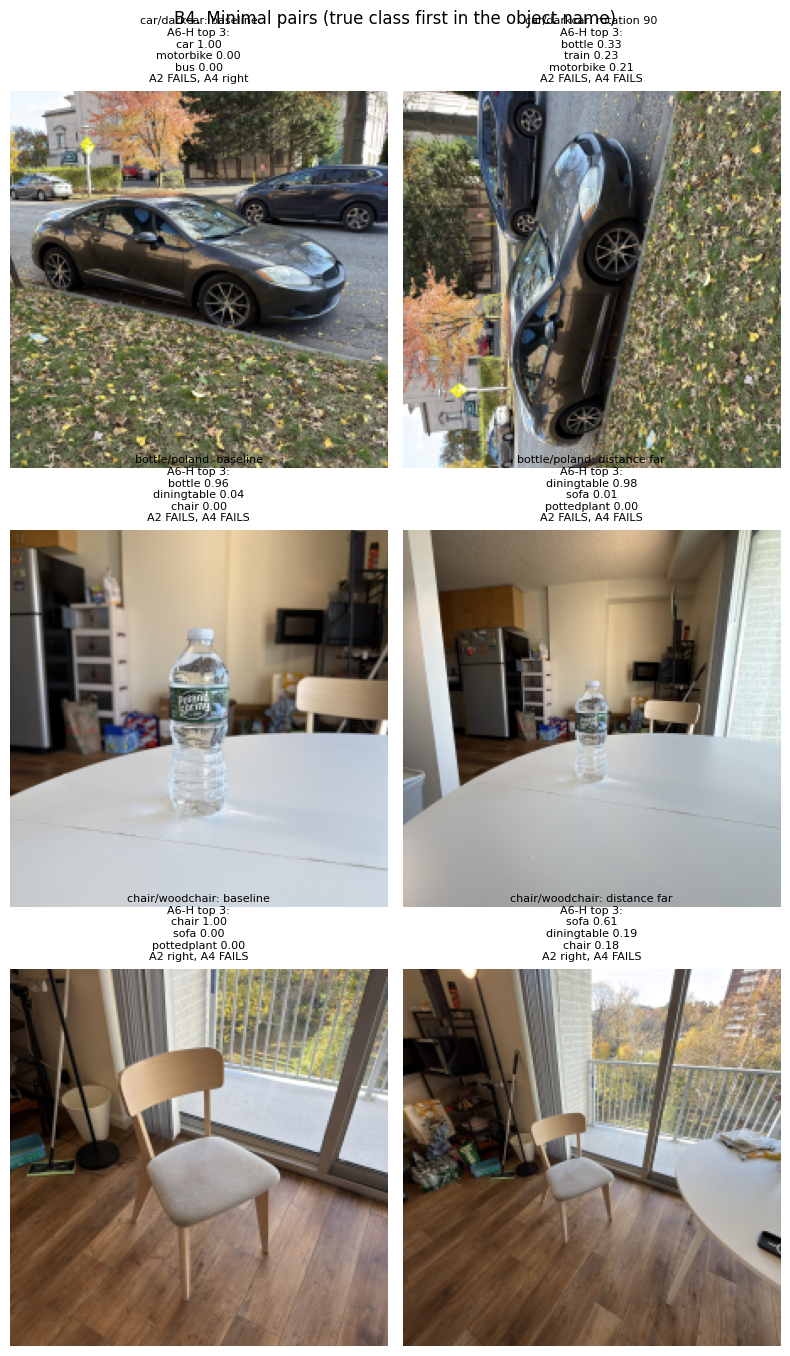

B4 photos saved: ['pair1_car_darkcar_baseline.jpg', 'pair1_car_darkcar_rotation_90.jpg', 'pair2_bottle_poland_baseline.jpg', 'pair2_bottle_poland_distance_far.jpg', 'pair3_chair_woodchair_baseline.jpg', 'pair3_chair_woodchair_distance_far.jpg']


In [ ]:
# B4: candidate minimal pairs from the B3 series: each manipulated photo against its object's baseline. A pair counts when
# A6-H is right on one photo and wrong on the other. PAIRS picks three pairs from different objects with at most one rotation;
# if fewer than three such pairs exist, it completes them with the largest falls in A6-H's true-class probability (say so).
p6 = B3_PROBS["A6-H"]
baseline_of = {r["object"]: i for i, r in enumerate(recs224) if r["factor"] == "rotation" and r["condition"] == "0"}
cands = []
for i, r in enumerate(recs224):
    if r["condition"] == B3_FACTORS[r["factor"]][0]:
        continue                                                # the baseline repeated as each factor's first condition
    j, c = baseline_of[r["object"]], r["cls"]
    right_base, right_man = p6[j].argmax() == c, p6[i].argmax() == c
    cands.append(dict(object=r["object"], factor=r["factor"], condition=r["condition"], base=j, manip=i,
                      flips=bool(right_base != right_man), base_p=float(p6[j, c]), manip_p=float(p6[i, c]),
                      drop=float(p6[j, c] - p6[i, c])))
cand_df = pd.DataFrame(cands).sort_values(["flips", "drop"], ascending=[False, False])
display(cand_df[["object", "factor", "condition", "flips", "base_p", "manip_p", "drop"]].head(20))


def pick_pairs(df):
    chosen, used, rotations = [], set(), 0
    for strict in (True, False):                              # first real flips, then the largest probability drops
        for _, row in df[df.flips == strict].sort_values("drop", ascending=False).iterrows():
            if len(chosen) == 3:
                return chosen
            if row.object in used or (row.factor == "rotation" and rotations == 1):
                continue
            chosen.append(row)
            used.add(row.object)
            rotations += row.factor == "rotation"
    return chosen


PAIRS = pick_pairs(cand_df)          # or choose your own rows from cand_df
n_flip = sum(bool(p.flips) for p in PAIRS)
if n_flip < 3:
    print(f"Only {n_flip} pair(s) where A6-H is right on one photo and wrong on the other; "
          f"{3 - n_flip} completed with the largest falls in A6-H's true-class probability.")


def top3(p):
    k = np.argsort(p)[::-1][:3]
    return "\n".join(f"{CLASSES[i]} {p[i]:.2f}" for i in k)


fig, ax = plt.subplots(len(PAIRS), 2, figsize=(8, 4.6 * len(PAIRS)), squeeze=False)
for r, pair in enumerate(PAIRS):
    for q, (i, label) in enumerate([(pair.base, "baseline"), (pair.manip, f"{pair.factor} {pair.condition}")]):
        c = recs224[i]["cls"]
        fails = ", ".join(f"{m} {'right' if B3_PROBS[m][i].argmax() == c else 'FAILS'}" for m in ("A2", "A4"))
        ax[r, q].imshow(recs224[i]["image"])
        ax[r, q].set_title(f"{pair.object}: {label}\nA6-H top 3:\n{top3(p6[i])}\n{fails}", fontsize=8)
        ax[r, q].axis("off")
fig.suptitle("B4. Minimal pairs (true class first in the object name)")
plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "B4_pairs.png", dpi=150)
plt.show()

# Save the B4 photos to photos/B4/ so they go into the submission zip (shrink_photos copies everything under photos/):
# the original photo files, and for a rotation pair the rotated baseline made by rotate_photo.
import glob, shutil
B4_DIR = os.path.join(PHOTO_DIR, "B4")
os.makedirs(B4_DIR, exist_ok=True)
for k, pair in enumerate(PAIRS, 1):
    obj_dir = os.path.join(B3_DIR, pair.object)
    base_file = [p for p in photo_files(obj_dir) if os.path.splitext(os.path.basename(p))[0] == "baseline"][0]
    tag = f"pair{k}_{pair.object.replace('/', '_')}"
    shutil.copy(base_file, os.path.join(B4_DIR, f"{tag}_baseline{os.path.splitext(base_file)[1].lower()}"))
    if pair.factor == "rotation":
        Image.fromarray(rotate_photo(base_file, int(pair.condition), 1024)).save(
            os.path.join(B4_DIR, f"{tag}_rotation_{pair.condition}.jpg"), quality=90)
    else:
        stem = f"{pair.factor}_{pair.condition}"
        f = [p for p in photo_files(obj_dir) if os.path.splitext(os.path.basename(p))[0] == stem][0]
        shutil.copy(f, os.path.join(B4_DIR, f"{tag}_{stem}{os.path.splitext(f)[1].lower()}"))
print("B4 photos saved:", sorted(os.listdir(B4_DIR)))

## B5: one repair

In [ ]:
# B5 needs the VOC crops again: X224, y and the Part A split were loaded in the reload check above (adapt with idx_train only).
if "X224" not in globals():
    X224, y, img_id, is_test = load_crops(224)
    idx_train, idx_val, idx_test = make_splits(img_id, is_test)
print(X224.shape, len(idx_train), "training crops")

(16719, 224, 224, 3) 7541 training crops


In [ ]:
# B5 (1/4): choose the factor and condition to repair, from B3 alone. A factor's A6-H drop is its baseline accuracy minus its
# worst condition's accuracy; since all factors share the baseline, this is the non-baseline condition where A6-H is least
# accurate. Ties: rotation, occlusion, our factor, then the conditions' order (min keeps the first).
base_acc = B3_ACC[("A6-H", "rotation", "0")][0]
options = [(f, c, B3_ACC[("A6-H", f, c)][0]) for f in FACTORS for c in B3_FACTORS[f][1:]
           if not np.isnan(B3_ACC[("A6-H", f, c)][0])]
for f in FACTORS:
    worst = min(a for g, c, a in options if g == f)
    print(f"{f:10s} A6-H drop = {base_acc:.1f} - {worst:.1f} = {base_acc - worst:+.1f}")
FACTOR, CONDITION, worst_acc = min(options, key=lambda t: t[2])
print(f"\nRepair: {FACTOR} = {CONDITION} (A6-H {worst_acc:.1f} vs baseline {base_acc:.1f})")
if worst_acc >= base_acc:
    print("No condition drops below the baseline: repairing the least accurate non-baseline condition anyway.")

rotation   A6-H drop = 0.9 - 0.6 = +0.3
occlusion  A6-H drop = 0.9 - 0.8 = +0.1
distance   A6-H drop = 0.9 - 0.5 = +0.4

Repair: distance = far (A6-H 0.5 vs baseline 0.9)


In [ ]:
import os, glob, shutil
for f in ["siamese_5", "tabby_5"]:
    for p in glob.glob(f"{PHOTO_DIR}/B1/cat/{f}.*"):
        os.remove(p); print("deleted", p)
print(len(glob.glob(PHOTO_DIR + '/B1/cat/*')), "B1 cat photos")

!unzip -o -q /content/p1_photos_B5.zip -d /content/tmp_b5
shutil.copytree("/content/tmp_b5/photos/B5", f"{PHOTO_DIR}/B5", dirs_exist_ok=True)
print(len(glob.glob(PHOTO_DIR + '/B5/*/*/*.jpg')), "B5 photos")

deleted /content/drive/MyDrive/p1/photos/B1/cat/siamese_5.jpg
deleted /content/drive/MyDrive/p1/photos/B1/cat/tabby_5.jpg
10 B1 cat photos
20 B5 photos


In [ ]:
# B5 (2/4): BEFORE the repair, photograph 10 adaptation photos under this condition (2 per class, objects not in B3, B4 or
# the held-out test; photos/B5/adapt/<class>/<object>.jpg) and the held-out pair per class (photos/B5/heldout/<class>/
# ordinary.jpg and challenge.jpg; for rotation only ordinary.jpg). The held-out predictions stay hidden until (4/4).
check_photos(MY_CLASSES, CHOSEN_FACTOR, b5_factor=FACTOR)
X_ad, y_ad, P_ad = load_b5_adapt(os.path.join(PHOTO_DIR, 'B5', 'adapt'), 224, FACTOR, CONDITION)
print(len(y_ad), "adaptation photos:", [os.path.relpath(p, PHOTO_DIR) for p in P_ad])
assert len(y_ad) == 10, "expected 10 adaptation photos (2 per class)"

5 problems:
  B5/adapt/bicycle: redbike1, redbike2 is a B3 object
  B5/adapt/bottle: fiji, poland is a B3 object
  B5/adapt/chair: whitechair, woodchair is a B3 object
  B5/adapt/car: darkcar, whitesuv is a B3 object
  B5/adapt/cat: siamese is a B3 object
10 adaptation photos: ['B5/adapt/bicycle/redbike1.jpg', 'B5/adapt/bicycle/redbike2.jpg', 'B5/adapt/bottle/fiji.jpg', 'B5/adapt/bottle/poland.jpg', 'B5/adapt/car/darkcar.jpg', 'B5/adapt/car/whitesuv.jpg', 'B5/adapt/cat/siamese.jpg', 'B5/adapt/cat/siamese2.jpg', 'B5/adapt/chair/whitechair.jpg', 'B5/adapt/chair/woodchair.jpg']


In [ ]:
# B5 (3/4): one fine-tuning run of A6-H, settings and stopping rule fixed before the run. Each update mixes 8 random VOC
# training crops (no repeats within a batch) with 8 adaptation photos drawn with replacement; horizontal flips (p = 0.5);
# AdamW, one learning rate 1e-5 for all parameters, weight decay 1e-2; the 19-way head is kept; stop after 100 updates and
# keep the final model.
import copy, time
B5_SETTINGS = dict(updates=100, voc_per_batch=8, adapt_per_batch=8, lr=1e-5, weight_decay=1e-2, flips=True,
                   stopping="fixed 100 updates, final model kept")
print(B5_SETTINGS)

a6h, prep_a6h = MODELS["A6-H"]
repaired = copy.deepcopy(a6h).to(DEV)
opt = torch.optim.AdamW(repaired.parameters(), lr=B5_SETTINGS["lr"], weight_decay=B5_SETTINGS["weight_decay"])
torch.manual_seed(0)
rng = np.random.default_rng(0)
t0 = time.perf_counter()
repaired.train()
for step in range(1, B5_SETTINGS["updates"] + 1):
    voc_ids = rng.choice(idx_train, B5_SETTINGS["voc_per_batch"], replace=False)
    ad_ids = rng.choice(len(y_ad), B5_SETTINGS["adapt_per_batch"], replace=True)
    xb = torch.cat([prep_a6h(X224[voc_ids]), prep_a6h(X_ad[ad_ids])]).to(DEV)
    yb = torch.from_numpy(np.concatenate([y[voc_ids], y_ad[ad_ids]])).long().to(DEV)
    flip = torch.rand(len(yb), device=xb.device) < 0.5
    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)
    loss = F.cross_entropy(repaired(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step()
    if step == 1 or step % 10 == 0:
        print(f"update {step:3d} | loss {loss.item():.4f}")
repaired.eval()
print(f"repair run: {time.perf_counter() - t0:.0f} s")
torch.save({k: v.detach().cpu() for k, v in repaired.state_dict().items()}, Path(CKPT_DIR) / "a6_h_repaired.pt")

{'updates': 100, 'voc_per_batch': 8, 'adapt_per_batch': 8, 'lr': 1e-05, 'weight_decay': 0.01, 'flips': True, 'stopping': 'fixed 100 updates, final model kept'}
update   1 | loss 1.4404
update  10 | loss 0.0026
update  20 | loss 0.0636
update  30 | loss 0.0097
update  40 | loss 0.0057
update  50 | loss 0.0037
update  60 | loss 0.0043
update  70 | loss 0.0058
update  80 | loss 0.0404
update  90 | loss 0.0049
update 100 | loss 0.0057
repair run: 269 s


In [39]:
# B5 (4/4): original vs repaired A6-H, six rows of mean per-class accuracy with counts. The held-out photos are loaded and
# predicted only now, after the repair run is fixed. Each held-out row has one photo per class, so it moves in steps of 0.2.
held = load_b5_heldout(os.path.join(PHOTO_DIR, 'B5', 'heldout'), 224, FACTOR, CONDITION)
b3_cond = [r for r in recs224 if r["factor"] == FACTOR and r["condition"] == CONDITION]
held_ord = [r for r in held if r["condition"] == "ordinary"]
held_ch = [r for r in held if r["condition"] != "ordinary"]
sets = [(f"B3 at {FACTOR} = {CONDITION}", b3_cond), ("B3, all images once (b3_unique)", b3_unique(recs224)),
        ("held-out ordinary", held_ord), (f"held-out {FACTOR} = {CONDITION}", held_ch)]

PROBS_B5 = {}
rows = []
for label, recs in sets:
    imgs, ys = np.stack([r["image"] for r in recs]), np.array([r["cls"] for r in recs])
    row = {"evaluation set": label, "n": len(recs)}
    for name, model in (("A6-H", a6h), ("A6-H-repaired", repaired)):
        PROBS_B5[(label, name)] = predict_proba(model, imgs, prep_a6h, DEV)
        row[name] = acc5(ys, PROBS_B5[(label, name)].argmax(1))[0]
    rows.append(row)
row = {"evaluation set": "B1", "n": len(y1)}
for name, model in (("A6-H", a6h), ("A6-H-repaired", repaired)):
    row[name] = acc5(y1, predict_proba(model, X1_224, prep_a6h, DEV).argmax(1))[0]
rows.append(row)
row = {"evaluation set": "VOC test (19 classes)", "n": len(idx_test)}
for name, model in (("A6-H", a6h), ("A6-H-repaired", repaired)):
    row[name] = mean_per_class_accuracy(y[idx_test], predict_proba(model, X224, prep_a6h, DEV, idx=idx_test))[0]
rows.append(row)
b5_table = pd.DataFrame(rows)
b5_table["change"] = b5_table["A6-H-repaired"] - b5_table["A6-H"]
b5_table.to_csv(Path(RESULTS_DIR) / "b5_table.csv", index=False)
display(b5_table.style.format({"A6-H": "{:.1%}", "A6-H-repaired": "{:.1%}", "change": "{:+.1%}"}).hide(axis="index"))

# b5_results.csv: the held-out photos and the B3 photos at the repaired condition, for both models
b3_relabel = [dict(r, condition=f"{FACTOR}_{CONDITION}") for r in b3_cond]
rows = []
for name in ("A6-H", "A6-H-repaired"):
    rows += b5_rows(held_ord + held_ch, name, np.concatenate([PROBS_B5[("held-out ordinary", name)],
                                                             PROBS_B5[(f"held-out {FACTOR} = {CONDITION}", name)]]))
    rows += b5_rows(b3_relabel, name, PROBS_B5[(f"B3 at {FACTOR} = {CONDITION}", name)])
write_b5_csv(rows, os.path.join(RESULTS_DIR, 'b5_results.csv'))

evaluation set,n,A6-H,A6-H-repaired,change
B3 at distance = far,10,50.0%,90.0%,+40.0%
"B3, all images once (b3_unique)",70,72.9%,95.7%,+22.9%
held-out ordinary,5,100.0%,100.0%,+0.0%
held-out distance = far,5,40.0%,80.0%,+40.0%
B1,52,86.0%,98.0%,+12.0%
VOC test (19 classes),8381,92.2%,91.7%,-0.5%


wrote 40 rows to /content/drive/MyDrive/p1/results/b5_results.csv


Before you submit: `shrink_photos()` copies your photos, upright and at 1024 px, to `p1/photos_small/` for the zip.